## TP4 -- Florian ANDRE (ING4 Majeure Cybersécurité, groupe 1)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Prétraitement des données

In [2]:
dataset = pd.read_csv("lending-club-data.csv")

/tmp/ipykernel_10659/841648227.py:1: DtypeWarning: Columns (19: desc, 47: next_pymnt_d) have mixed types. Specify dtype option on import or set low_memory=False.
  dataset = pd.read_csv("lending-club-data.csv")


In [3]:
# Affichage des 5 premières lignes du dataset
dataset.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,sub_grade_num,delinq_2yrs_zero,pub_rec_zero,collections_12_mths_zero,short_emp,payment_inc_ratio,final_d,last_delinq_none,last_record_none,last_major_derog_none
0,1077501,1296599,5000,5000,4975,36 months,10.65,162.87,B,B2,...,0.4,1.0,1.0,1.0,0,8.14350,20141201T000000,1,1,1
1,1077430,1314167,2500,2500,2500,60 months,15.27,59.83,C,C4,...,0.8,1.0,1.0,1.0,1,2.39320,20161201T000000,1,1,1
2,1077175,1313524,2400,2400,2400,36 months,15.96,84.33,C,C5,...,1.0,1.0,1.0,1.0,0,8.25955,20141201T000000,1,1,1
3,1076863,1277178,10000,10000,10000,36 months,13.49,339.31,C,C1,...,0.2,1.0,1.0,1.0,0,8.27585,20141201T000000,0,1,1
4,1075269,1311441,5000,5000,5000,36 months,7.90,156.46,A,A4,...,0.8,1.0,1.0,1.0,0,5.21533,20141201T000000,1,1,1


In [4]:
# types des variables
dataset.dtypes

id                         int64
member_id                  int64
loan_amnt                  int64
funded_amnt                int64
funded_amnt_inv            int64
                          ...   
payment_inc_ratio        float64
final_d                      str
last_delinq_none           int64
last_record_none           int64
last_major_derog_none      int64
Length: 68, dtype: object

In [5]:
# dimensions du dataset
print(f'Nombre de lignes : {dataset.shape[0]} | Nombre de colonnes : {dataset.shape[1]}')

Nombre de lignes : 122607 | Nombre de colonnes : 68


In [6]:
# Création de la nouvelle variable safe_loans
# La consigne : +1 si le prêt est sûr (bad_loans == 0), -1 s'il est risqué (bad_loans == 1)
dataset['safe_loans'] = dataset['bad_loans'].apply(lambda x: 1 if x == 0 else -1)

In [7]:
# Supprimer la variable bad_loans d'origine
dataset = dataset.drop(columns=['bad_loans'])

In [8]:
# Sélection des variables explicatives requises + la cible 'safe_loans'
features = [
    'grade',
    'sub_grade',
    'short_emp',
    'emp_length_num',
    'home_ownership',
    'dti',
    'purpose',
    'term',
    'last_delinq_none',
    'last_major_derog_none',
    'revol_util',
    'total_rec_late_fee',
]

In [9]:
# On isole le sous-ensemble de données avec les variables explicatives et la cible
colonnes_utiles = features + ['safe_loans']
dataset_final = dataset[colonnes_utiles]

print('\n--- Dimensions du jeu de données après sélection ---')
print(dataset_final.shape)
print('\nPremières lignes du jeu de données prêt pour la modélisation :')
display(dataset_final.head())


--- Dimensions du jeu de données après sélection ---
(122607, 13)

Premières lignes du jeu de données prêt pour la modélisation :


,grade,sub_grade,short_emp,emp_length_num,home_ownership,dti,purpose,term,last_delinq_none,last_major_derog_none,revol_util,total_rec_late_fee,safe_loans
0,B,B2,0,11,RENT,27.65,credit_card,36 months,1,1,83.7,0.00,1
1,C,C4,1,1,RENT,1.00,car,60 months,1,1,9.4,0.00,-1
2,C,C5,0,11,RENT,8.72,small_business,36 months,1,1,98.5,0.00,1
3,C,C1,0,11,RENT,20.00,other,36 months,0,1,21.0,16.97,1
4,A,A4,0,4,RENT,11.20,wedding,36 months,1,1,28.3,0.00,1


## Equilibrage des classes et rééchantillonnage

In [10]:
# Constat de déséquilibre
print("--- Répartition avant équilibrage ---")
print(dataset_final['safe_loans'].value_counts())

--- Répartition avant équilibrage ---
safe_loans
 1    99457
-1    23150
Name: count, dtype: int64


In [11]:
# Réalisation du sous-échantillonnage
# Séparation des deux classes
risky_loans = dataset_final[dataset_final['safe_loans'] == -1]
safe_loans = dataset_final[dataset_final['safe_loans'] == 1]

# On échantillonne les crédits sûrs pour qu'il y en ait autant que de crédits risqués
safe_loans_sampled = safe_loans.sample(n=len(risky_loans), random_state=42)

# Concaténation des deux sous-ensembles pour obtenir un jeu équilibré
df_balanced = pd.concat([risky_loans, safe_loans_sampled])

# Mélange (shuffle) des lignes pour éviter d'avoir toutes les classes groupées
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

In [12]:
# Application du one-hot encoding sur le DataFrame équilibré
# pandas.get_dummies convertit automatiquement les colonnes de type 'object' ou 'category'
df_encoded = pd.get_dummies(df_balanced, drop_first=True)

print("--- Dimensions après One-Hot Encoding ---")
print(df_encoded.shape)

print('\nPremières colonnes du DataFrame encodé :')
print(df_encoded.columns[:10])  # Affiche un aperçu des nouvelles colonnes

--- Dimensions après One-Hot Encoding ---
(46300, 63)

Premières colonnes du DataFrame encodé :
Index(['short_emp', 'emp_length_num', 'dti', 'last_delinq_none',
       'last_major_derog_none', 'revol_util', 'total_rec_late_fee',
       'safe_loans', 'grade_B', 'grade_C'],
      dtype='str')


## Séparation des données

In [13]:
from sklearn.model_selection import train_test_split

# Séparation des features (X) et de la cible (y)
X = df_encoded.drop(columns=['safe_loans'])
y = df_encoded['safe_loans']

# Division 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Taille du jeu d'entraînement : {X_train.shape[0]} lignes")
print(f'Taille du jeu de test : {X_test.shape[0]} lignes')

Taille du jeu d'entraînement : 37040 lignes
Taille du jeu de test : 9260 lignes


## Construction du modèle et visualisation

In [14]:
from sklearn.tree import DecisionTreeClassifier

# a. Modèle principal avec max_depth=6
clf_deep = DecisionTreeClassifier(max_depth=6, random_state=42)
clf_deep.fit(X_train, y_train)

# b. Modèle réduit avec max_depth=2 pour la visualisation
clf_shallow = DecisionTreeClassifier(max_depth=2, random_state=42)
clf_shallow.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

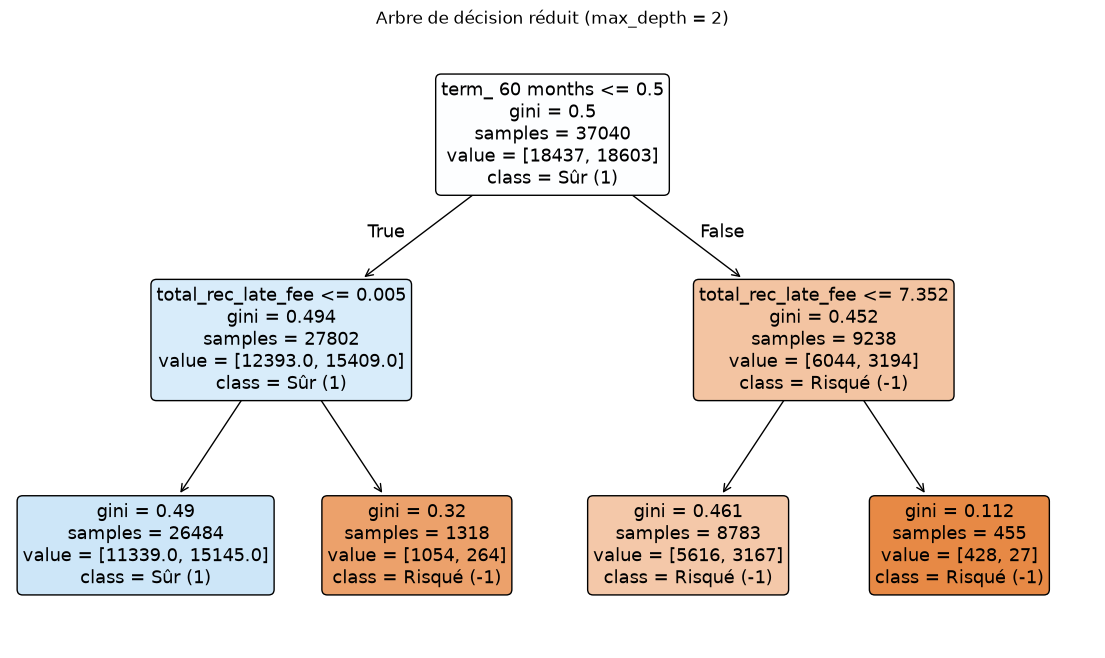

In [15]:
# Visualisation de l'arbre de décision réduit
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 8))
plot_tree(
    clf_shallow,
    feature_names=X.columns,
    class_names=['Risqué (-1)', 'Sûr (1)'],
    filled=True,
    rounded=True,
)
plt.title('Arbre de décision réduit (max_depth = 2)')
plt.show()

## Prédictions et évaluation

In [16]:
import pandas as pd

# Sélection de 2 exemples sûrs (1) et 2 exemples risqués (-1) dans le jeu de test
safe_ex = X_test[y_test == 1].head(2)
risky_ex = X_test[y_test == -1].head(2)
selected_examples = pd.concat([safe_ex, risky_ex])

# Prédictions de classe et de probabilités
preds = clf_deep.predict(selected_examples)
probs = clf_deep.predict_proba(selected_examples)

# Affichage des résultats
for i, (idx, row) in enumerate(selected_examples.iterrows()):
  print(f'--- Exemple {i+1} (Vraie classe : {y_test.loc[idx]}) ---')
  print(f'Classe prédite : {preds[i]}')
  print(f'Probabilités [Risqué (-1), Sûr (1)] : {probs[i]}\n')

--- Exemple 1 (Vraie classe : 1) ---
Classe prédite : -1
Probabilités [Risqué (-1), Sûr (1)] : [0.65238095 0.34761905]

--- Exemple 2 (Vraie classe : 1) ---
Classe prédite : -1
Probabilités [Risqué (-1), Sûr (1)] : [0.63893016 0.36106984]

--- Exemple 3 (Vraie classe : -1) ---
Classe prédite : 1
Probabilités [Risqué (-1), Sûr (1)] : [0.38452061 0.61547939]

--- Exemple 4 (Vraie classe : -1) ---
Classe prédite : -1
Probabilités [Risqué (-1), Sûr (1)] : [0.9047619 0.0952381]



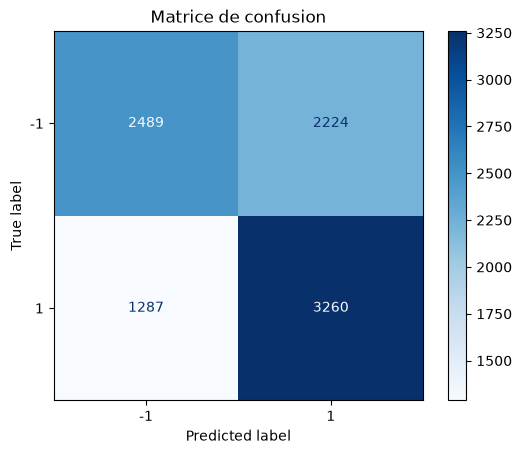

In [17]:
# Matrice de confusion
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Prédictions sur l'ensemble du jeu de test
y_pred = clf_deep.predict(X_test)

# Calcul de la matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# Affichage graphique
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=clf_deep.classes_
)
disp.plot(cmap=plt.cm.Blues)
plt.title('Matrice de confusion')
plt.show()

## Evaluation avancée du modèle

In [18]:
## Calcul exactitude, précision
def calculer_precision(y_true, y_pred):
  """Calcule le taux de prédictions correctes (Accuracy / Exactitude).
  """
  return np.mean(y_true == y_pred)


# Exemple d'utilisation
acc_train = calculer_precision(y_train, clf_deep.predict(X_train))
acc_test = calculer_precision(y_test, clf_deep.predict(X_test))

print(f"Précision globale (Train) : {acc_train:.4f}")
print(f"Précision globale (Test)  : {acc_test:.4f}")

Précision globale (Train) : 0.6381
Précision globale (Test)  : 0.6208


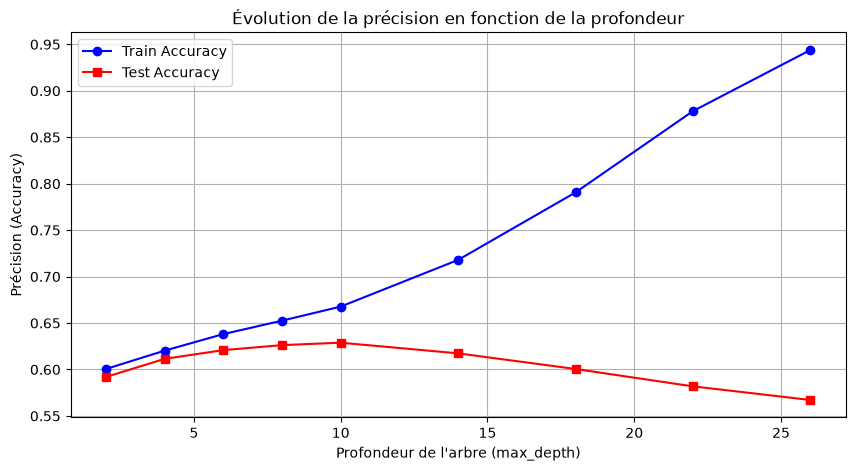

In [19]:
# Comparaison des profondeurs sur Train et Test
from sklearn.tree import DecisionTreeClassifier

profondeurs = [2, 4, 6, 8, 10, 14, 18, 22, 26]
acc_train_list = []
acc_test_list = []

for depth in profondeurs:
  clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
  clf.fit(X_train, y_train)

  acc_train_list.append(calculer_precision(y_train, clf.predict(X_train)))
  acc_test_list.append(calculer_precision(y_test, clf.predict(X_test)))

# Graphique d'évaluation
plt.figure(figsize=(10, 5))
plt.plot(
    profondeurs,
    acc_train_list,
    marker="o",
    label="Train Accuracy",
    color="blue",
)
plt.plot(
    profondeurs, acc_test_list, marker="s", label="Test Accuracy", color="red"
)
plt.xlabel("Profondeur de l'arbre (max_depth)")
plt.ylabel("Précision (Accuracy)")
plt.title("Évolution de la précision en fonction de la profondeur")
plt.grid(True)
plt.legend()
plt.show()

In [21]:
# Mesure TP et FP
from sklearn.metrics import confusion_matrix

# Sur le modèle max_depth=6
y_pred_test = clf_deep.predict(X_test)
cm = confusion_matrix(y_test, y_pred_test, labels=[-1, 1])

# Extraction : TN (Risqué bien prédit), FP (Prédit sûr mais risqué), FN (Prédit risqué mais sûr), TP (Sûr bien prédit)
tn, fp, fn, tp = cm.ravel()

print(f"--- Bilan des Erreurs (sur {len(y_test)} prêts de test) ---")
print(
    f"Faux Positifs (FP) [Prêt risqué accordé] : {fp} ({(fp/len(y_test))*100:.2f}%)"
)
print(
    f"Faux Négatifs (FN) [Prêt refusé à tort]   : {fn} ({(fn/len(y_test))*100:.2f}%)"
)

--- Bilan des Erreurs (sur 9260 prêts de test) ---
Faux Positifs (FP) [Prêt risqué accordé] : 2224 (24.02%)
Faux Négatifs (FN) [Prêt refusé à tort]   : 1287 (13.90%)


In [22]:
# Comparaison de différentes configurations d'hyperparamètres
configurations = [
    {
        "name": "Arbre Complexe (Overfitting)",
        "params": {
            "max_depth": 20,
            "min_samples_split": 2,
            "min_samples_leaf": 1,
        },
    },
    {
        "name": "Arbre Tronqué (Défaut - max_depth 6)",
        "params": {
            "max_depth": 6,
            "min_samples_split": 2,
            "min_samples_leaf": 1,
        },
    },
    {
        "name": "Arbre Régularisé (Feuilles & Splits)",
        "params": {
            "max_depth": 10,
            "min_samples_split": 50,
            "min_samples_leaf": 20,
        },
    },
    {
        "name": "Arbre Très Simple (Underfitting)",
        "params": {
            "max_depth": 2,
            "min_samples_split": 100,
            "min_samples_leaf": 50,
        },
    },
]

results = []

for config in configurations:
  clf = DecisionTreeClassifier(**config["params"], random_state=42)
  clf.fit(X_train, y_train)

  acc_tr = clf.score(X_train, y_train)
  acc_te = clf.score(X_test, y_test)
  num_nodes = clf.tree_.node_count  # Taille de l'arbre (nombre total de nœuds)

  results.append({
      "Modèle": config["name"],
      "Nœuds": num_nodes,
      "Acc Train": round(acc_tr, 4),
      "Acc Test": round(acc_te, 4),
      "Écart (Overfit)": round(acc_tr - acc_te, 4),
  })

df_res = pd.DataFrame(results)
display(df_res)

,Modèle,Nœuds,Acc Train,Acc Test,Écart (Overfit)
0,Arbre Complexe (Overfitting),9857,0.8364,0.5927,0.2437
1,Arbre Tronqué (Défaut - max_depth 6),101,0.6381,0.6208,0.0173
2,Arbre Régularisé (Feuilles & Splits),531,0.6609,0.6343,0.0266
3,Arbre Très Simple (Underfitting),7,0.6005,0.5919,0.0086
